# 5. Probability distributions and the central limit theorem

**Track:** core &nbsp;·&nbsp; **Prerequisites:** Chapters 1, 3 and 4

**Reading:** Taylor, ch. 5, 10 and 11 · Bevington & Robinson, ch. 2 ·
Fornasini, ch. 5 and 6 · Rouaud, ch. I and III

Part I treated an uncertainty as a standard deviation and combined
standard deviations in quadrature, without saying much about the
distributions behind them. This part of the book supplies the missing
probability and statistics. This chapter introduces the distributions that
occur most often in measurement, and explains why one of them, the normal
distribution, appears almost everywhere.

1. A random variable is described by its distribution; its mean and
   variance are the two numbers error analysis uses most.
2. The binomial, Poisson and normal distributions are related as limits of
   one another.
3. The uniform, exponential and Cauchy distributions each describe a common
   situation, and the Cauchy distribution is a warning.
4. The central limit theorem explains why sums and means of many
   independent contributions are normally distributed, and how fast.
5. The sample statistics of Chapter 4 have their own distributions: $\chi^2$,
   Student's $t$ and $F$.

In [1]:
import numpy as np
import matplotlib.pyplot as plt
from scipy import stats

try:
    import errprop as ep
except ImportError:          # running from a clone without `pip install -e .`
    import sys
    sys.path.insert(0, "../..")
    import errprop as ep

ep.use_style()
rng = np.random.default_rng(105)

## 5.1 Random variables and their distributions

A measured value that changes unpredictably from one repetition to the
next is a **random variable**. For a discrete variable (a count) the
distribution is a set of probabilities $P(k)$ with $\sum_k P(k) = 1$; for a
continuous variable it is a **probability density** $p(x)$, with
$P(a < x < b) = \int_a^b p(x)\,\mathrm dx$ and $\int p(x)\,\mathrm dx = 1$.

Two numbers summarise a distribution. The **mean** (expectation value)

$$ \mu = \langle x\rangle = \int x\,p(x)\,\mathrm dx $$

locates it, and the **variance**

$$ \sigma^2 = \langle (x - \mu)^2\rangle = \langle x^2\rangle - \mu^2 $$

measures its width. Why the variance, rather than, say, the mean absolute
deviation? Because variances of independent quantities *add*. For
independent $x$ and $y$,

$$ \operatorname{var}(x + y) = \langle (\delta x + \delta y)^2\rangle
  = \sigma_x^2 + 2\langle\delta x\,\delta y\rangle + \sigma_y^2 = \sigma_x^2 + \sigma_y^2 , $$

since $\langle\delta x\,\delta y\rangle = \langle\delta x\rangle\langle\delta y\rangle = 0$.
No other measure of width combines this simply, and this one property is
the root of quadrature addition (Section 1.4) and of the whole of
Chapter 3.

Higher moments describe the shape: the **skewness**
$\gamma_1 = \langle (x-\mu)^3\rangle/\sigma^3$ measures asymmetry, the
**excess kurtosis** $\gamma_2 = \langle (x-\mu)^4\rangle/\sigma^4 - 3$ measures
how heavy the tails are compared with a normal distribution, for which
both are zero.

## 5.2 Binomial, Poisson and normal

**Binomial.** An experiment is repeated $n$ times; each trial succeeds with
probability $p$, independently of the others. The number of successes $k$
has the binomial distribution

$$ P(k) = \binom{n}{k} p^k (1-p)^{n-k}, \qquad \mu = np, \qquad \sigma^2 = np(1-p) . $$

The variance follows from the additivity above: $k$ is a sum of $n$
independent trials, each 1 with probability $p$ and 0 otherwise, so each has
variance $p - p^2$. A typical use is an *efficiency*: if a detector records
$k$ of $n$ particles, the efficiency $\hat\varepsilon = k/n$ has standard
uncertainty $\sqrt{\hat\varepsilon(1-\hat\varepsilon)/n}$, which is small
both when the efficiency is close to 0 and when it is close to 1.

**Poisson.** If $n$ is very large and $p$ very small, with $np = \mu$ fixed,
the binomial distribution becomes

$$ P(k) = \frac{\mu^k e^{-\mu}}{k!}, \qquad \text{mean } \mu, \qquad \text{variance } \mu . $$

This is the distribution of the number of independent rare events in a
fixed interval: radioactive decays, photons, cosmic rays, molecules
crossing a surface. That the variance equals the mean is the origin of the
$\sqrt N$ rule of counting experiments (Chapter 6).

**Normal.** For large $\mu$ the Poisson distribution, and for large $n$ the
binomial, approach the normal (Gaussian) distribution

$$ p(x) = \frac{1}{\sigma\sqrt{2\pi}}\exp\!\left[-\frac{(x-\mu)^2}{2\sigma^2}\right] , $$

for which the probability of lying within $1\sigma$, $2\sigma$ and $3\sigma$
of the mean is 68.27 %, 95.45 % and 99.73 %.

In [2]:
for k_sigma in (1, 2, 3):
    print(f"P(|x - mu| < {k_sigma} sigma) = {stats.norm.cdf(k_sigma) - stats.norm.cdf(-k_sigma):.4f}")

# binomial with fixed n p = 4 approaching Poisson; Poisson approaching normal
k = np.arange(0, 15)
for n in (8, 40, 400):
    d = np.abs(stats.binom.pmf(k, n, 4 / n) - stats.poisson.pmf(k, 4)).max()
    print(f"binomial(n={n:3d}, p={4 / n:.3f}) vs Poisson(4): largest difference in P(k) = {d:.4f}")
for mu in (4, 25, 100):
    kk = np.arange(0, int(mu + 8 * np.sqrt(mu)))
    d = np.abs(stats.poisson.pmf(kk, mu) - stats.norm.pdf(kk, mu, np.sqrt(mu))).max() / stats.poisson.pmf(int(mu), mu)
    print(f"Poisson({mu:3d}) vs normal: largest difference relative to the peak = {d:.3f}")

P(|x - mu| < 1 sigma) = 0.6827
P(|x - mu| < 2 sigma) = 0.9545
P(|x - mu| < 3 sigma) = 0.9973
binomial(n=  8, p=0.500) vs Poisson(4): largest difference in P(k) = 0.0781
binomial(n= 40, p=0.100) vs Poisson(4): largest difference in P(k) = 0.0105
binomial(n=400, p=0.010) vs Poisson(4): largest difference in P(k) = 0.0010
Poisson(  4) vs normal: largest difference relative to the peak = 0.131
Poisson( 25) vs normal: largest difference relative to the peak = 0.049
Poisson(100) vs normal: largest difference relative to the peak = 0.024


The Poisson distribution of mean 4 is visibly skewed (panel (a) of the
figure below); at a mean of 25 the normal approximation is good to a few
per cent of the peak height, which is why counts of more than about 20 are
usually treated as normal.

## 5.3 Three more distributions

**Uniform.** $p(x) = 1/(2a)$ on $[-a, a]$, with $\sigma = a/\sqrt3$. It
describes rounding by a digital display (Section 1.3), the phase of an
unsynchronised oscillation, and any Type B statement "somewhere within
$\pm a$". The sum of two independent uniform variables of equal width has
a **triangular** distribution, $\sigma = a/\sqrt 6$ for half-width $a$.

**Exponential.** $p(t) = \lambda e^{-\lambda t}$ for $t \ge 0$, with mean
and standard deviation both $1/\lambda$. It is the distribution of the
waiting time between Poisson events and of the lifetime of an unstable
particle or excited state. Its skewness is 2: the mean lies well above the
median $\ln 2/\lambda$.

**Cauchy (Lorentzian).**
$p(x) = \dfrac{1}{\pi}\dfrac{\Gamma/2}{(x - x_0)^2 + (\Gamma/2)^2}$, the shape
of a resonance line, of the energy distribution of an unstable state, and
of the ratio of two independent zero-mean normal variables. Its tails fall
off so slowly ($\propto x^{-2}$) that the integrals for the mean and the
variance do not converge. The distribution has a centre $x_0$ and a width
$\Gamma$, but no mean and no standard deviation. The consequence is
striking: the average of $N$ Cauchy-distributed readings has *the same*
distribution as a single reading, and averaging does not help at all
(panel (d)). Error analysis built on standard deviations silently assumes
distributions for which they exist, and a ratio with an uncertain
denominator (Section 12.3) is where the assumption usually breaks.

In [3]:
for N in (1, 10, 1000):
    means = rng.standard_cauchy((20_000, N)).mean(axis=1)
    iqr = np.subtract(*np.quantile(means, [0.75, 0.25]))
    print(f"Cauchy: interquartile range of the mean of {N:4d} readings = {iqr:.3f}  (single reading: 2.000)")

Cauchy: interquartile range of the mean of    1 readings = 2.019  (single reading: 2.000)
Cauchy: interquartile range of the mean of   10 readings = 2.001  (single reading: 2.000)


Cauchy: interquartile range of the mean of 1000 readings = 2.053  (single reading: 2.000)


## 5.4 The central limit theorem

Let $x_1, \dots, x_N$ be independent, with the same distribution of mean
$\mu$ and finite variance $\sigma^2$. The **central limit theorem** states
that the distribution of their mean $\bar x$ approaches a normal
distribution of mean $\mu$ and standard deviation $\sigma/\sqrt N$ as $N$
grows, *whatever the original distribution*. (Only the finite variance is
required, which is exactly what the Cauchy distribution lacks.) The same
holds for sums, and, with some conditions, for sums of variables with
different distributions, provided no single term dominates.

This is why measurement errors are so often normal: an error is usually
the sum of many small, independent disturbances (vibration, electrical
noise, temperature fluctuations, reading), none of them dominant. It is
also why the *mean* of a few readings is closer to normal than the
readings themselves, which justifies the use of normal-theory intervals for
means even when individual readings are not normal.

How fast does it happen? For a sum of $N$ independent terms, the skewness
falls as $\gamma_1/\sqrt N$ and the excess kurtosis as $\gamma_2/N$. A
symmetric distribution such as the uniform one converges very fast (the sum
of three uniforms is already hard to distinguish from a normal
distribution); a skewed one such as the exponential converges slowly.

In [4]:
print(" N    skewness of the mean of N exponentials    expected 2/sqrt(N)")
for N in (1, 2, 5, 10, 30, 100):
    m = rng.exponential(1.0, (100_000, N)).mean(axis=1)
    print(f"{N:3d}                 {stats.skew(m):.3f}                          {2 / np.sqrt(N):.3f}")

# how good is the normal 68 % interval for the mean of N exponential readings?
print("\n N    P(|mean - mu| < sigma/sqrt(N))")
for N in (1, 3, 10, 30):
    m = rng.exponential(1.0, (200_000, N)).mean(axis=1)
    print(f"{N:3d}         {np.mean(np.abs(m - 1) < 1 / np.sqrt(N)):.3f}")

 N    skewness of the mean of N exponentials    expected 2/sqrt(N)
  1                 2.021                          2.000
  2                 1.398                          1.414
  5                 0.907                          0.894
 10                 0.638                          0.632
 30                 0.365                          0.365
100                 0.205                          0.200

 N    P(|mean - mu| < sigma/sqrt(N))
  1         0.864
  3         0.715
 10         0.691


 30         0.684


For a single exponential reading, $\pm 1\sigma$ covers 86 % instead of 68 %.
For the mean of three readings the figure is already 72 %, and for ten
readings 69 %: the *width* of the normal approximation becomes usable
quickly, while the *asymmetry* of the distribution of the mean persists
much longer (panel (c) of the figure below).

## 5.5 Distributions of sample statistics: $\chi^2$, $t$ and $F$

Chapter 4 used three results without proof. They follow from three
distributions, all derived from the normal one.

* **Chi-square.** If $z_1, \dots, z_\nu$ are independent standard normal
  variables, $\chi^2 = \sum z_i^2$ has the $\chi^2$ distribution with $\nu$
  degrees of freedom: mean $\nu$, variance $2\nu$. For normal readings,
  $(N-1)s^2/\sigma^2$ has this distribution with $\nu = N-1$; the "lost"
  degree of freedom is the one used to compute $\bar x$. This is the source
  of the uncertainty of the standard deviation,
  $u_s/s \approx 1/\sqrt{2(N-1)}$ (Section 4.3), and of the spread
  $\sqrt{2/\nu}$ of a reduced chi-square (Section 11.4).
* **Student's $t$.** $t = (\bar x - \mu)/(s/\sqrt N)$ has the $t$ distribution
  with $N-1$ degrees of freedom, whose heavier tails account for the
  uncertainty of $s$ (Section 4.4).
* **$F$.** The ratio of two independent reduced chi-squares,
  $F = (\chi^2_1/\nu_1)/(\chi^2_2/\nu_2)$, compares two variances
  (Chapter 8).

A simulation confirms the first two for samples of five normal readings.

In [5]:
N, sigma = 5, 2.0
x = rng.normal(10.0, sigma, (200_000, N))
s = x.std(axis=1, ddof=1)
q = (N - 1) * s**2 / sigma**2
t = (x.mean(axis=1) - 10.0) / (s / np.sqrt(N))
print(f"(N-1) s^2 / sigma^2:  mean {q.mean():.3f} (chi-square: {N - 1}),  variance {q.var():.3f} (chi-square: {2 * (N - 1)})")
print(f"P(|t| < 1): simulated {np.mean(np.abs(t) < 1):.4f},  Student t(4) {stats.t.cdf(1, 4) - stats.t.cdf(-1, 4):.4f},  normal 0.6827")
print(f"mean of s = {s.mean():.3f} for sigma = {sigma}:  s underestimates sigma on average by {1 - s.mean() / sigma:.1%}")

(N-1) s^2 / sigma^2:  mean 3.998 (chi-square: 4),  variance 8.034 (chi-square: 8)
P(|t| < 1): simulated 0.6269,  Student t(4) 0.6261,  normal 0.6827
mean of s = 1.879 for sigma = 2.0:  s underestimates sigma on average by 6.0%


The last line is worth noting: although $s^2$ is an unbiased estimate of
$\sigma^2$, its square root $s$ is not an unbiased estimate of $\sigma$;
for five readings it is about 6 % low on average. Bias and other properties
of estimators are the subject of Chapter 7.

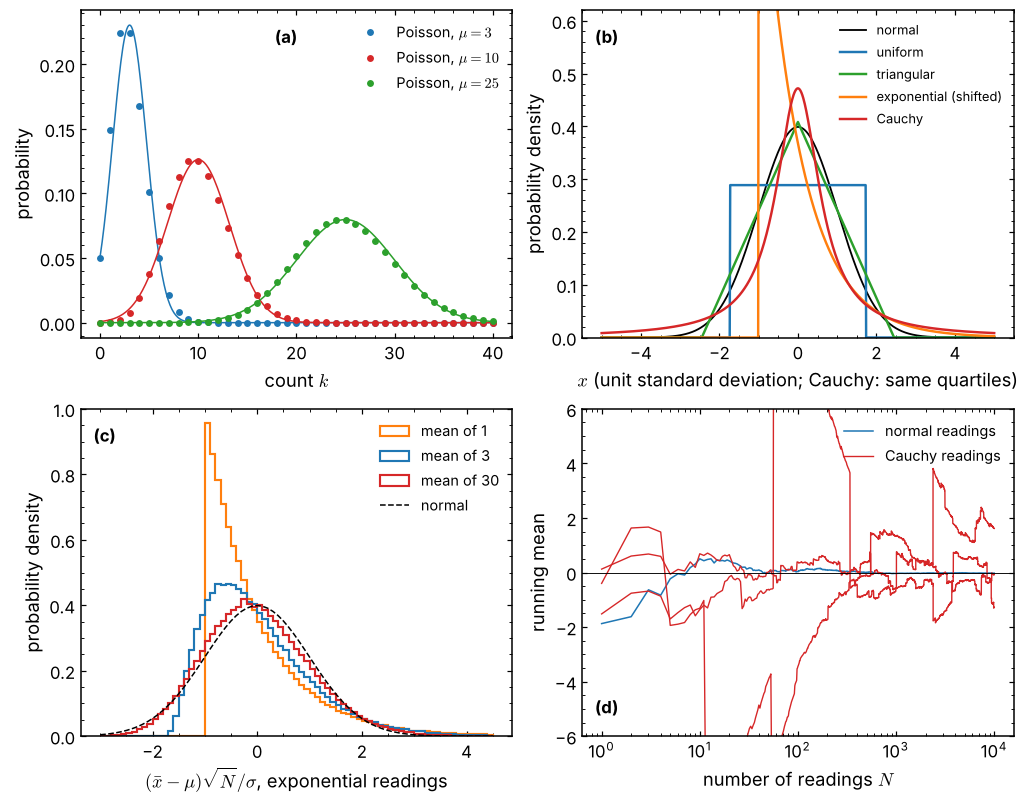

In [6]:
fig, axes = plt.subplots(2, 2, figsize=(9.2, 7.2))

ax = axes[0, 0]
kk = np.arange(0, 41)
for mu, c in ((3, "C0"), (10, "C3"), (25, "C2")):
    ax.plot(kk, stats.poisson.pmf(kk, mu), "o", ms=3.5, color=c, label=f"Poisson, $\\mu={mu}$")
    xx = np.linspace(0, 40, 400)
    ax.plot(xx, stats.norm.pdf(xx, mu, np.sqrt(mu)), "-", color=c, lw=1)
ax.set_xlabel("count $k$"); ax.set_ylabel("probability")
ax.legend(loc="upper right"); ep.panel_label(ax, "(a)", x=0.45)

ax = axes[0, 1]
xx = np.linspace(-5, 5, 801)
ax.plot(xx, stats.norm.pdf(xx), "k", lw=1.2, label="normal")
ax.plot(xx, stats.uniform.pdf(xx, -np.sqrt(3), 2 * np.sqrt(3)), "C0", label="uniform")
ax.plot(xx, stats.triang.pdf(xx, 0.5, -np.sqrt(6), 2 * np.sqrt(6)), "C2", label="triangular")
ax.plot(xx, stats.expon.pdf(xx + 1), "C1", label="exponential (shifted)")
ax.plot(xx, stats.cauchy.pdf(xx, 0, 0.6745), "C3", label="Cauchy")
ax.set_xlabel("$x$ (unit standard deviation; Cauchy: same quartiles)"); ax.set_ylabel("probability density")
ax.set_ylim(0, 0.62); ax.legend(loc="upper right", fontsize=8.5); ep.panel_label(ax, "(b)")

ax = axes[1, 0]
bins = np.linspace(-3, 4.5, 76)
for N, c in ((1, "C1"), (3, "C0"), (30, "C3")):
    m = rng.exponential(1.0, (200_000, N)).mean(axis=1)
    z = (m - 1) * np.sqrt(N)
    ax.hist(z, bins=bins, density=True, histtype="step", lw=1.4, color=c, label=f"mean of {N}")
ax.plot(bins, stats.norm.pdf(bins), "k--", lw=1, label="normal")
ax.set_xlabel(r"$(\bar x - \mu)\sqrt{N}/\sigma$, exponential readings"); ax.set_ylabel("probability density")
ax.set_ylim(0, 1.0); ax.legend(loc="upper right"); ep.panel_label(ax, "(c)")

ax = axes[1, 1]
nn = np.arange(1, 10_001)
ax.plot(nn, np.cumsum(rng.normal(0, 1, nn.size)) / nn, "C0", lw=1, label="normal readings")
for i in range(3):
    ax.plot(nn, np.cumsum(rng.standard_cauchy(nn.size)) / nn, color="C3", lw=0.9,
            label="Cauchy readings" if i == 0 else None)
ax.axhline(0, color="k", lw=0.6)
ax.set_xscale("log"); ax.set_ylim(-6, 6)
ax.set_xlabel("number of readings $N$"); ax.set_ylabel("running mean")
ax.legend(loc="upper right"); ep.panel_label(ax, "(d)", y=0.12)
plt.show()

**(a)** Poisson distributions (points) and normal distributions of the same
mean and variance (lines). **(b)** Five distributions scaled to unit
standard deviation (the Cauchy distribution, which has none, is scaled to
the same quartiles as the normal one). **(c)** The central limit theorem
at work on exponential readings: the distribution of the mean approaches
the normal one as $N$ grows, the skewness disappearing last. **(d)** Running
means: for normal readings the mean settles as $1/\sqrt N$; for Cauchy
readings it never settles, and occasional huge readings throw it about at
any $N$.

## Summary

* Variances of independent quantities add; this single fact underlies
  quadrature and the propagation law.
* Binomial $\to$ Poisson for rare events, Poisson $\to$ normal for large
  counts; the Poisson variance equals its mean.
* The uniform distribution describes rounding and bounded Type B
  information, the exponential distribution waiting times and lifetimes.
* The Cauchy distribution has no mean or variance; averaging does not
  reduce its spread. Ratios with uncertain denominators lead there.
* By the central limit theorem, sums and means of many independent
  contributions with finite variance become normal, symmetric ones fast,
  skewed ones slowly.
* The $\chi^2$, $t$ and $F$ distributions describe sample variances and the
  statistics built from them.

## Exercises

1. A detector registers 912 of 1000 incident particles. Give the efficiency
   with its binomial uncertainty. Why is the Poisson formula $\sqrt{912}$
   wrong here?
2. Show that the triangular distribution of half-width $a$ has standard
   deviation $a/\sqrt 6$, and verify by summing two simulated uniform
   variables.
3. Simulate the ratio $x/y$ of two independent normal variables with means
   $0$ and $1$ and unit standard deviations. Compare its histogram with a
   Cauchy distribution. What changes when $y$ has mean 5?
4. Repeat the convergence study of Section 5.4 for the sum of $N$ values
   drawn from a distribution with skewness 6 (for example, a lognormal with
   $\sigma_{\ln} = 1$). How large must $N$ be for the skewness of the mean to
   fall below 0.2?
5. Using the $\chi^2$ distribution, find the exact 68 % interval for
   $\sigma$ given $s = 1.0$ from $N = 5$ readings. Compare with
   $s \pm s/\sqrt{2(N-1)}$.

---

**Previous:** [4. Repeated measurements](../part1_measurement/04_repeated_measurements.ipynb) &nbsp;·&nbsp; **Next:** [6. Counting statistics](06_counting_statistics.ipynb)